In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
%matplotlib inline

In [2]:
# Set random seed so the data is reproducible
np.random.seed(32)

# Create 36 monthly dates
dates = pd.date_range(
    start="2022-01-01",
    periods=36,
    freq="MS"
)

# Month number and time index
month = dates.month.to_numpy()
t = np.arange(36)

# Create seasonal pattern: higher usage around summer
seasonal = (
    48 * np.sin(2 * np.pi * (month - 4) / 12)
    + 10 * np.cos(2 * np.pi * (month - 7) / 12)
)

# Create electricity usage
usage = (
    420
    + 1.4 * t
    + seasonal
    + np.random.normal(0, 6, 36)
)

# Create DataFrame
df = pd.DataFrame({
    "Month": dates,
    "Electricity_GWh": np.round(usage, 1)
})

# Display first five rows
df.head()

,Month,Electricity_GWh
0,2022-01-01,359.9
1,2022-02-01,377.1
2,2022-03-01,397.3
3,2022-04-01,424.6
4,2022-05-01,459.3


In [3]:
# Save dataset
df.to_csv("electricity_usage.csv", index=False)

# Load the CSV file
df = pd.read_csv(
    "electricity_usage.csv",
    parse_dates=["Month"]
)

# Display dataset
display(df.head())

# Check dataset information
print("Dataset shape:", df.shape)
print("Missing values:")
print(df.isnull().sum())

,Month,Electricity_GWh
0,2022-01-01,359.9
1,2022-02-01,377.1
2,2022-03-01,397.3
3,2022-04-01,424.6
4,2022-05-01,459.3


Dataset shape: (36, 2)
Missing values:
Month              0
Electricity_GWh    0
dtype: int64


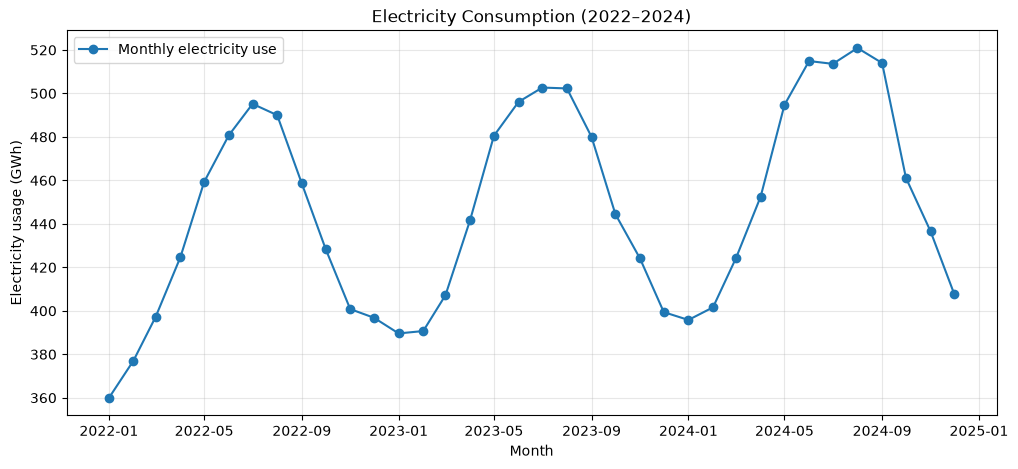

In [4]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["Month"],
    df["Electricity_GWh"],
    marker="o",
    label="Monthly electricity use"
)

plt.title("Electricity Consumption (2022–2024)")
plt.xlabel("Month")
plt.ylabel("Electricity usage (GWh)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [5]:
# Calculate rolling 12-month average
df["Rolling_Mean"] = df["Electricity_GWh"].rolling(
    window=12,
    center=True,
    min_periods=1
).mean()

# Extract calendar month
df["Month_Number"] = df["Month"].dt.month

# Average electricity use for each calendar month
monthly_average = df.groupby(
    "Month_Number"
)["Electricity_GWh"].mean()

print("Average electricity usage by month:")
print(monthly_average.round(2))

Average electricity usage by month:
Month_Number
1     381.77
2     389.80
3     409.60
4     439.60
5     478.17
6     497.23
7     503.83
8     504.40
9     484.20
10    444.73
11    420.50
12    401.27
Name: Electricity_GWh, dtype: float64


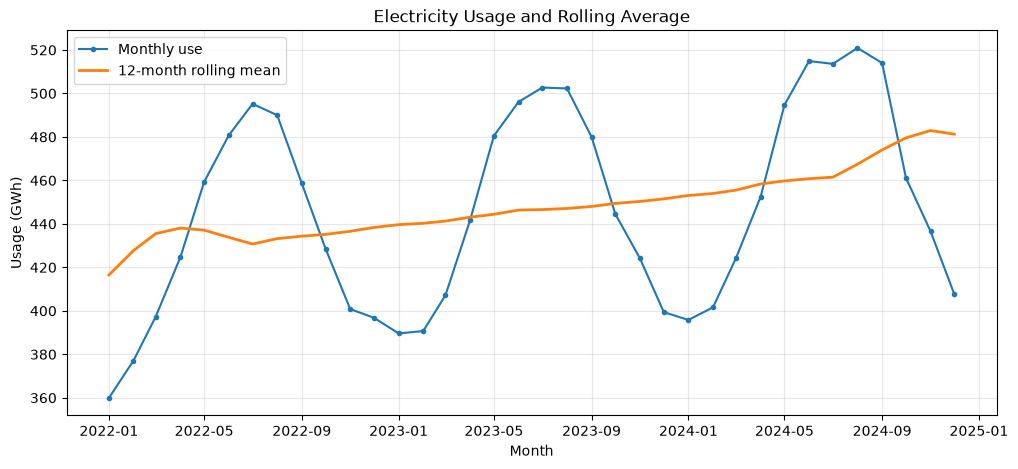

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["Month"], df["Electricity_GWh"],
    label="Monthly use", marker="o", markersize=3
)

plt.plot(
    df["Month"], df["Rolling_Mean"],
    label="12-month rolling mean", linewidth=2
)

plt.title("Electricity Usage and Rolling Average")
plt.xlabel("Month")
plt.ylabel("Usage (GWh)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

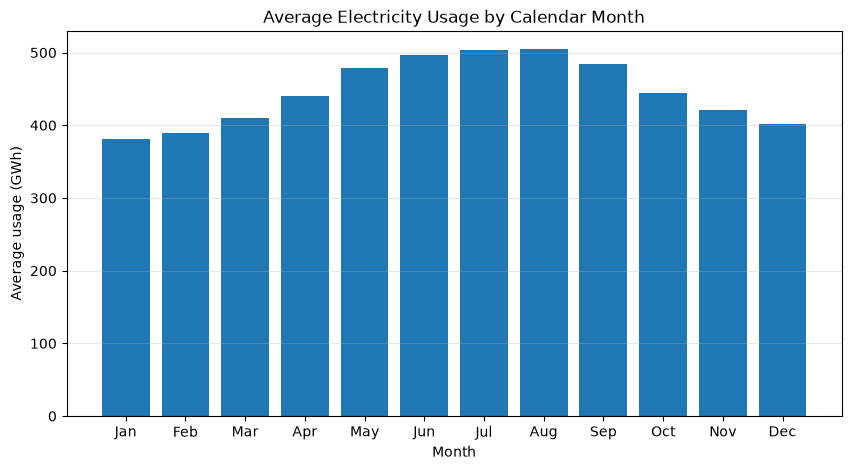

Highest average month: Aug
Lowest average month: Jan


In [7]:
month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(10, 5))

plt.bar(
    month_names,
    [monthly_average[m] for m in range(1, 13)]
)

plt.title("Average Electricity Usage by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average usage (GWh)")
plt.grid(axis="y", alpha=0.3)

plt.show()

print("Highest average month:",
      month_names[monthly_average.values.argmax()])

print("Lowest average month:",
      month_names[monthly_average.values.argmin()])

In [8]:
usage = df["Electricity_GWh"].to_numpy()

# First 24 months: training
train_usage = usage[:24]

# Last 12 months: testing
test_usage = usage[24:]

train_t = np.arange(24)
test_t = np.arange(24, 36)

test_dates = df["Month"].iloc[24:]

print("Training months:", len(train_usage))
print("Testing months:", len(test_usage))

Training months: 24
Testing months: 12


In [9]:
seasonal_naive = usage[12:24]

print("Seasonal-naive forecast for 2024:")

for date, value in zip(test_dates, seasonal_naive):
    print(date.strftime("%b %Y"), ":", round(value, 2), "GWh")

Seasonal-naive forecast for 2024:
Jan 2024 : 389.6 GWh
Feb 2024 : 390.7 GWh
Mar 2024 : 407.2 GWh
Apr 2024 : 441.7 GWh
May 2024 : 480.5 GWh
Jun 2024 : 496.1 GWh
Jul 2024 : 502.7 GWh
Aug 2024 : 502.3 GWh
Sep 2024 : 480.0 GWh
Oct 2024 : 444.5 GWh
Nov 2024 : 424.1 GWh
Dec 2024 : 399.4 GWh


In [10]:
# Fit a straight-line trend
slope, intercept = np.polyfit(
    train_t,
    train_usage,
    1
)

# Calculate trend values
train_trend = intercept + slope * train_t

# Calculate residuals (actual value minus trend)
residuals = train_usage - train_trend

print("Monthly growth:", round(slope, 2), "GWh")
print("Trend intercept:", round(intercept, 2))

Monthly growth: 1.88 GWh
Trend intercept: 417.01


In [11]:
train_months = df["Month"].dt.month.to_numpy()[:24]

seasonal_offsets = {}

for m in range(1, 13):
    values = residuals[train_months == m]
    seasonal_offsets[m] = np.mean(values)

print("Seasonal offsets:")
print(seasonal_offsets)

Seasonal offsets:
{1: np.float64(-53.55234782608704), 2: np.float64(-46.28373913043487), 3: np.float64(-29.815130434782674), 4: np.float64(-0.7965217391304975), 5: np.float64(34.0720869565217), 6: np.float64(50.6906956521739), 7: np.float64(59.359304347826054), 8: np.float64(54.67791304347827), 9: np.float64(25.946521739130446), 10: np.float64(-8.734869565217366), 11: np.float64(-34.66626086956515), 12: np.float64(-50.897652173913)}


In [12]:
trend_seasonal = []

for i in test_t:
    month_number = int(df.loc[i, "Month"].month)

    trend_value = intercept + slope * i

    prediction = (
        trend_value + seasonal_offsets[month_number]
    )

    trend_seasonal.append(prediction)

trend_seasonal = np.array(trend_seasonal)

print("Trend-plus-seasonal forecast completed.")

Trend-plus-seasonal forecast completed.


In [13]:
def calculate_mape(actual, predicted):
    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    return np.mean(
        np.abs((actual - predicted) / actual)
    ) * 100


mape_naive = calculate_mape(
    test_usage,
    seasonal_naive
)

mape_trend_seasonal = calculate_mape(
    test_usage,
    trend_seasonal
)

print("Seasonal-naive MAPE:",
      round(mape_naive, 2), "%")

print("Trend-plus-seasonal MAPE:",
      round(mape_trend_seasonal, 2), "%")

if mape_naive != 0:
    improvement = (
        (mape_naive - mape_trend_seasonal)
        / mape_naive
    ) * 100

    print("Error reduction:",
          round(improvement, 2), "%")

Seasonal-naive MAPE: 3.17 %
Trend-plus-seasonal MAPE: 2.86 %
Error reduction: 9.77 %


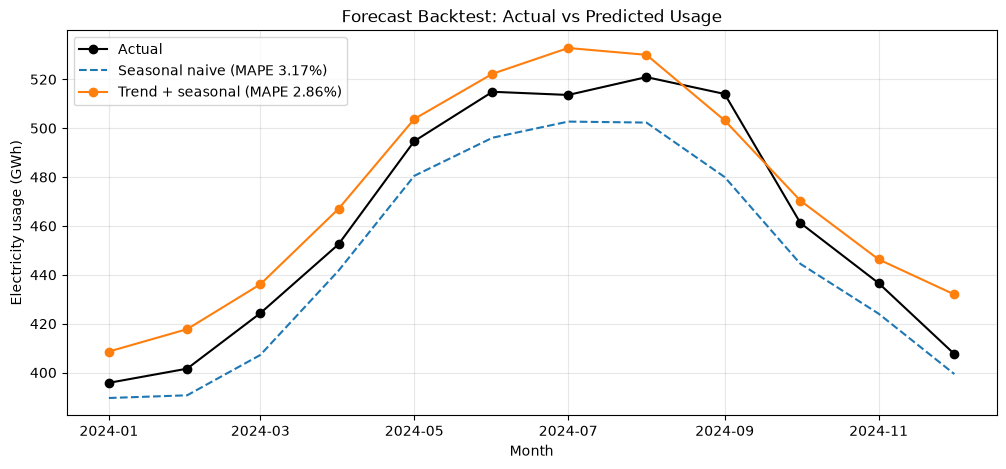

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(
    test_dates,
    test_usage,
    marker="o",
    color="black",
    label="Actual"
)

plt.plot(
    test_dates,
    seasonal_naive,
    linestyle="--",
    label=f"Seasonal naive (MAPE {mape_naive:.2f}%)"
)

plt.plot(
    test_dates,
    trend_seasonal,
    marker="o",
    label=f"Trend + seasonal (MAPE {mape_trend_seasonal:.2f}%)"
)

plt.title("Forecast Backtest: Actual vs Predicted Usage")
plt.xlabel("Month")
plt.ylabel("Electricity usage (GWh)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [15]:
# Fit trend using all available data
t_all = np.arange(36)

slope_all, intercept_all = np.polyfit(
    t_all,
    usage,
    1
)

all_trend = intercept_all + slope_all * t_all

# Calculate residuals
all_residuals = usage - all_trend

# Calculate seasonal offsets using all 36 months
all_months = df["Month"].dt.month.to_numpy()

all_offsets = {}

for m in range(1, 13):
    all_offsets[m] = np.mean(
        all_residuals[all_months == m]
    )

# Create dates for 2025
future_dates = pd.date_range(
    start="2025-01-01",
    periods=12,
    freq="MS"
)

future_t = np.arange(36, 48)

# Generate predictions
forecast = []

for i, date in zip(future_t, future_dates):
    trend_value = intercept_all + slope_all * i

    prediction = (
        trend_value + all_offsets[date.month]
    )

    forecast.append(prediction)

forecast = np.array(forecast)

# Create an approximate 95% uncertainty band
residual_std = np.std(all_residuals, ddof=1)

lower_band = forecast - 1.96 * residual_std
upper_band = forecast + 1.96 * residual_std

forecast_df = pd.DataFrame({
    "Month": future_dates,
    "Forecast_GWh": np.round(forecast, 2),
    "Lower_Band": np.round(lower_band, 2),
    "Upper_Band": np.round(upper_band, 2)
})

display(forecast_df)

,Month,Forecast_GWh,Lower_Band,Upper_Band
0,2025-01-01,418.80,333.18,504.41
1,2025-02-01,426.83,341.21,512.45
2,2025-03-01,446.63,361.01,532.25
3,2025-04-01,476.63,391.01,562.25
4,2025-05-01,515.20,429.58,600.81
5,2025-06-01,534.26,448.65,619.88
6,2025-07-01,540.86,455.25,626.48
7,2025-08-01,541.43,455.81,627.05
8,2025-09-01,521.23,435.61,606.85
9,2025-10-01,481.76,396.15,567.38


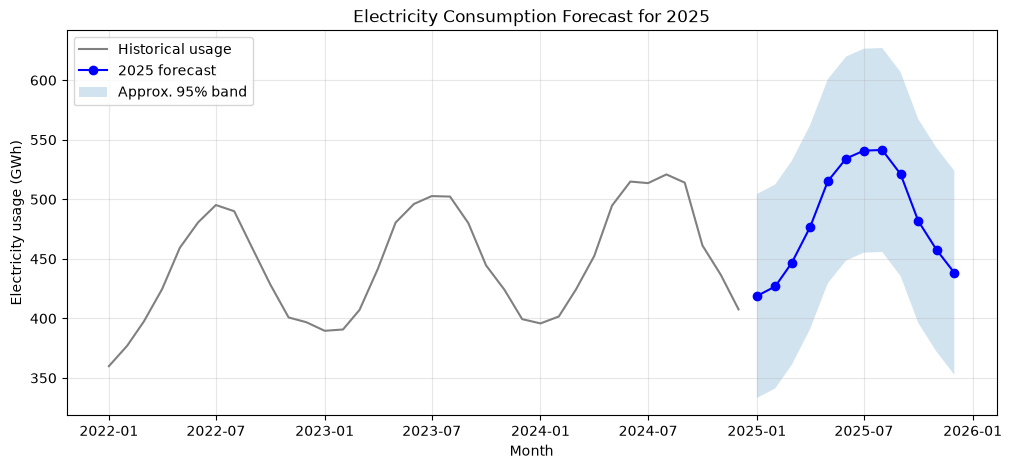

In [16]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["Month"],
    usage,
    color="gray",
    label="Historical usage"
)

plt.plot(
    future_dates,
    forecast,
    color="blue",
    marker="o",
    label="2025 forecast"
)

plt.fill_between(
    future_dates,
    lower_band,
    upper_band,
    alpha=0.2,
    label="Approx. 95% band"
)

plt.title("Electricity Consumption Forecast for 2025")
plt.xlabel("Month")
plt.ylabel("Electricity usage (GWh)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [17]:
annual_total = forecast.sum()

peak_index = np.argmax(forecast)
lowest_index = np.argmin(forecast)

annual_growth_percent = (
    slope_all * 12 / np.mean(usage)
) * 100

results = {
    "monthly_growth_GWh": round(float(slope_all), 2),
    "annual_growth_percent": round(float(annual_growth_percent), 2),
    "seasonal_naive_MAPE": round(float(mape_naive), 2),
    "trend_seasonal_MAPE": round(float(mape_trend_seasonal), 2),
    "forecast_2025_total_GWh": round(float(annual_total), 2),
    "peak_month": future_dates[peak_index].strftime("%B"),
    "peak_usage_GWh": round(float(forecast[peak_index]), 2),
    "lowest_forecast_month": future_dates[lowest_index].strftime("%B"),
    "lowest_forecast_GWh": round(float(forecast[lowest_index]), 2)
}

print("ENERGY CONSUMPTION FORECAST — PROJECT SUMMARY")
print("-" * 50)

for key, value in results.items():
    print(f"{key}: {value}")

ENERGY CONSUMPTION FORECAST — PROJECT SUMMARY
--------------------------------------------------
monthly_growth_GWh: 1.54
annual_growth_percent: 4.15
seasonal_naive_MAPE: 3.17
trend_seasonal_MAPE: 2.86
forecast_2025_total_GWh: 5799.47
peak_month: August
peak_usage_GWh: 541.43
lowest_forecast_month: January
lowest_forecast_GWh: 418.8


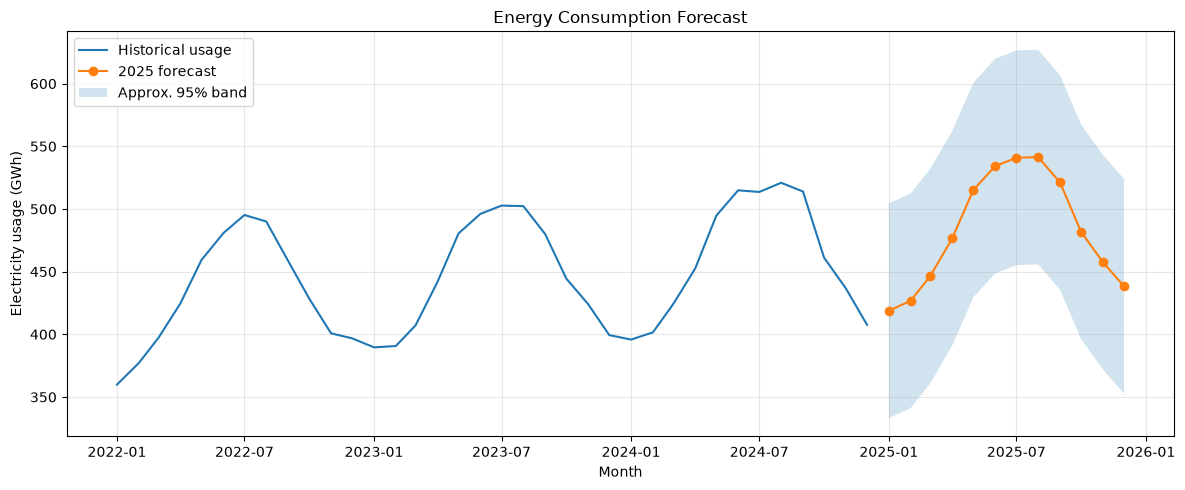

Saved chart.png and results.json


In [18]:
# Save the forecast chart
plt.figure(figsize=(12, 5))

plt.plot(df["Month"], usage, label="Historical usage")
plt.plot(future_dates, forecast, marker="o", label="2025 forecast")

plt.fill_between(
    future_dates,
    lower_band,
    upper_band,
    alpha=0.2,
    label="Approx. 95% band"
)

plt.title("Energy Consumption Forecast")
plt.xlabel("Month")
plt.ylabel("Electricity usage (GWh)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("chart.png", dpi=120)
plt.show()

# Save calculated results to JSON
with open("results.json", "w") as file:
    json.dump(results, file, indent=4)

print("Saved chart.png and results.json")